# DM ZG504 · Lab 2 — From clean data to decisions: OEE, statistics, SPC and machine learning
**Covers:** OEE and the loss tree · six big losses and Pareto · descriptive statistics, distributions and Q–Q plots · X̄–R control charts and run rules · process capability (Cp, Cpk, Pp, Ppk) · a first classification model (train/test split, leakage, confusion matrix, precision/recall, cost-based threshold)

**Time:** about 2 hours. **How to work:** run the cells from top to bottom. Complete the cells marked **`# TODO`** (usually one to four lines) and answer the ✍️ questions in the text cell under them. ✅/❌ checks tell you whether a result is right.

**The plant.** The same plant as in Lab 1, one week later (9–10 November 2026). Four machines (M01–M04) work three 480-minute shifts (A, B, C). You receive:

| File | One row is … | Used in |
|---|---|---|
| `shift_summary.csv` | one machine in one shift: shift length, planned and unplanned stop minutes, ideal cycle time (s), total and good count | Part A — OEE |
| `downtime_events.csv` | one unplanned stop with its reason and minutes | Part A — losses |
| `repair_times.csv` | the time to repair (minutes) of one breakdown | Part B — statistics |
| `bore_diameter.csv` | one subgroup of 5 bores measured every hour (mm); specification 25.000 ± 0.030 mm | Part C — SPC |
| `part_process_data.csv` | one part from M03 in production order: tool age, spindle temperature, coolant flow, feed, rework flag, scrap (1 = scrap) | Part D — ML |

In [1]:
# @title ▶ Setup — run this cell first (it creates the data files; you do not need to read it) { display-mode: "form" }
# Generates the files for Lab 2 into ./data (fixed seed: everyone gets the same data)
import os
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
os.makedirs("data", exist_ok=True)

# ---------- 1. shift summaries for OEE (2 days x 3 shifts x 4 machines) ----------
# each machine has a different main loss: M02 breakdowns, M04 slow running, M03 quality
prof = {  # ideal CT s, unplanned stop range (min), performance range, quality range
    "M01": (40, (15, 35), (0.92, 0.97), (0.985, 0.995)),
    "M02": (50, (60, 110), (0.92, 0.96), (0.98, 0.99)),
    "M03": (45, (15, 35), (0.90, 0.95), (0.90, 0.94)),
    "M04": (60, (20, 40), (0.74, 0.80), (0.98, 0.99)),
}
reason_w = {  # weights of downtime reasons per machine
    "M01": {"Breakdown": .3, "Setup / changeover": .4, "Minor stop / jam": .3},
    "M02": {"Breakdown": .75, "Setup / changeover": .1, "Minor stop / jam": .15},
    "M03": {"Breakdown": .2, "Setup / changeover": .5, "Minor stop / jam": .3},
    "M04": {"Breakdown": .2, "Setup / changeover": .2, "Minor stop / jam": .6},
}
rows, events = [], []
for date in ["2026-11-09", "2026-11-10"]:
    for shift in ["A", "B", "C"]:
        for m, (ict, dr, pr, qr) in prof.items():
            planned = 30 + (20 if (shift == "A" and date == "2026-11-09") else 0)   # break (+ planned PM)
            down = int(rng.integers(*dr))
            if m == "M02" and date == "2026-11-10" and shift == "C":
                planned, down = 330, 55          # planned overhaul; difficult restart afterwards
            run = 480 - planned - down
            total = int(run * 60 * rng.uniform(*pr) / ict)
            good = total - int(round(total * (1 - rng.uniform(*qr))))
            rows.append((date, shift, m, 480, planned, down, ict, total, good))
            k = int(rng.integers(2, 5))
            cuts = np.sort(rng.choice(np.arange(1, down), k - 1, replace=False))
            for mins in np.diff(np.r_[0, cuts, down]):
                r = rng.choice(list(reason_w[m]), p=list(reason_w[m].values()))
                events.append((date, shift, m, r, int(mins)))
shift_summary = pd.DataFrame(rows, columns=["date", "shift", "machine_id", "shift_min", "planned_stop_min",
                                            "unplanned_stop_min", "ideal_ct_s", "total_count", "good_count"])
downtime_events = pd.DataFrame(events, columns=["date", "shift", "machine_id", "reason", "minutes"])

# ---------- 2. time to repair of breakdowns (times are right-skewed: lognormal) ----------
repair = pd.DataFrame({"breakdown_no": np.arange(1, 301),
                       "repair_min": np.round(rng.lognormal(np.log(25), 0.6, 300), 1)})

# ---------- 3. bore diameter, 25 subgroups of 5 parts; tool wear shifts the mean from subgroup 19 ----------
mu = np.where(np.arange(1, 26) >= 19, 25.017, 25.002)
x = rng.normal(mu[:, None], 0.008, (25, 5)).round(4)
bore = pd.DataFrame(x, columns=[f"x{i}" for i in range(1, 6)])
bore.insert(0, "subgroup", np.arange(1, 26))
bore.insert(1, "time", pd.date_range("2026-11-09 06:30", periods=25, freq="1h").strftime("%Y-%m-%d %H:%M"))

# ---------- 4. part-level process data for the scrap classifier (time-ordered) ----------
n = 2000
tool_age = np.arange(n) % 400                              # tool changed every 400 parts
temp = 62 + 0.0015 * np.arange(n) + rng.normal(0, 1.5, n)  # slow upward drift
coolant = rng.normal(20, 1.5, n)
feed = rng.normal(0.20, 0.01, n)
logit = -5.6 + 0.0075 * tool_age + 0.35 * (temp - 62) - 0.45 * (coolant - 20) + 30 * (feed - 0.20)
scrap = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
rework_flag = np.where(rng.random(n) < 0.96, scrap, 0)     # filled in AFTER final inspection
ml = pd.DataFrame({"part_id": np.arange(500001, 500001 + n), "tool_age_parts": tool_age,
                   "spindle_temp_C": temp.round(2), "coolant_flow_lpm": coolant.round(2),
                   "feed_mm_rev": feed.round(4), "rework_flag": rework_flag, "scrap": scrap})

shift_summary.to_csv("data/shift_summary.csv", index=False)
downtime_events.to_csv("data/downtime_events.csv", index=False)
repair.to_csv("data/repair_times.csv", index=False)
bore.to_csv("data/bore_diameter.csv", index=False)
ml.to_csv("data/part_process_data.csv", index=False)
print("Lab 2 data written to ./data:", {f: len(pd.read_csv("data/" + f)) for f in sorted(os.listdir("data"))})

import matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

def check(ok, good, bad):
    print(("✅ " + good) if ok else ("❌ " + bad))

Lab 2 data written to ./data: {'bore_diameter.csv': 25, 'downtime_events.csv': 78, 'downtime_log.csv': 36, 'm03_spindle_temp.csv': 2835, 'machines.csv': 5, 'part_process_data.csv': 2000, 'production_events.csv': 12866, 'repair_times.csv': 300, 'shift_summary.csv': 24}


## Part A — OEE and loss analysis (≈ 35 min)
Overall Equipment Effectiveness answers *"of the time we planned to produce, how much produced good parts at ideal speed?"* It is built from the loss tree:

- **Planned production time** PPT = shift time − planned stops (breaks, planned maintenance)
- **Run time** RT = PPT − unplanned stops → **Availability** A = RT ÷ PPT
- **Performance** P = (ideal cycle time × total count) ÷ RT  — loses time to reduced speed and small stops
- **Quality** Q = good count ÷ total count
- **OEE = A × P × Q = (ideal cycle time × good count) ÷ PPT**

Watch the units: ideal cycle time is in **seconds**, the stop times are in **minutes**.

In [2]:
ss = pd.read_csv("data/shift_summary.csv")
ss["ppt_min"] = ss["shift_min"] - ss["planned_stop_min"]
ss["run_min"] = ss["ppt_min"] - ss["unplanned_stop_min"]
ss.head()

,date,shift,machine_id,shift_min,planned_stop_min,unplanned_stop_min,ideal_ct_s,total_count,good_count,ppt_min,run_min
0,2026-11-09,A,M01,480,50,32,40,568,562,430,398
1,2026-11-09,A,M02,480,50,78,50,403,396,430,352
2,2026-11-09,A,M03,480,50,27,45,495,452,430,403
3,2026-11-09,A,M04,480,50,30,60,304,299,430,400
4,2026-11-09,B,M01,480,30,34,40,593,586,450,416


In [3]:
# TODO A1: add the columns availability, performance, quality and oee (as fractions, e.g. 0.85)
ss["availability"] = ss["run_min"] / ss["ppt_min"]

ss["performance"] = (
    ss["ideal_ct_s"] * ss["total_count"]
) / (60 * ss["run_min"])

ss["quality"] = ss["good_count"] / ss["total_count"]

ss["oee"] = (
    ss["availability"]
    * ss["performance"]
    * ss["quality"]
)

check(np.allclose(ss["oee"], ss["ideal_ct_s"] * ss["good_count"] / (60 * ss["ppt_min"])) and ss["performance"].max() <= 1,
      "OEE columns correct", "check the formulas and the seconds/minutes conversion")
ss[["date", "shift", "machine_id", "availability", "performance", "quality", "oee"]].round(3).head(8)

✅ OEE columns correct


,date,shift,machine_id,availability,performance,quality,oee
0,2026-11-09,A,M01,0.926,0.951,0.989,0.871
1,2026-11-09,A,M02,0.819,0.954,0.983,0.767
2,2026-11-09,A,M03,0.937,0.921,0.913,0.788
3,2026-11-09,A,M04,0.930,0.760,0.984,0.695
4,2026-11-09,B,M01,0.924,0.950,0.988,0.868
5,2026-11-09,B,M02,0.820,0.930,0.988,0.754
6,2026-11-09,B,M03,0.924,0.930,0.915,0.787
7,2026-11-09,B,M04,0.936,0.765,0.981,0.702


**A2. OEE per machine for the two days.** There are two ways to combine six shifts: average the six shift OEE values, or add up the minutes and counts first and compute OEE once (a **ratio of sums**). Look at M02's shift C on 10 November before you decide.

In [4]:
print(ss[ss["machine_id"] == "M02"][["date", "shift", "ppt_min", "oee"]].round(3))

mean_of_shifts = ss.groupby("machine_id")["oee"].mean()
# TODO A2: OEE per machine as a ratio of sums: sum of (ideal_ct_s × good_count) ÷ sum of (60 × ppt_min), per machine
num = (ss["ideal_ct_s"] * ss["good_count"]).groupby(ss["machine_id"]).sum()

den = (60 * ss["ppt_min"]).groupby(ss["machine_id"]).sum()

ratio_of_sums = num / den

pd.DataFrame({"mean of shift OEE": mean_of_shifts, "ratio of sums": ratio_of_sums}).round(4)

          date shift  ppt_min    oee
1   2026-11-09     A      430  0.767
5   2026-11-09     B      450  0.754
9   2026-11-09     C      450  0.798
13  2026-11-10     A      450  0.713
17  2026-11-10     B      450  0.698
21  2026-11-10     C      150  0.594


,mean of shift OEE,ratio of sums
machine_id,,
M01,0.8828,0.8828
M02,0.7208,0.7363
M03,0.7989,0.7990
M04,0.7018,0.7019


✍️ **Q A2.** Why do the two methods agree for M01, M03 and M04 but not for M02? Which number is correct for M02 and why?

*Your answer:* Answer:

For M01, M03, and M04, the six shifts have very similar planned production times (ppt_min is mostly 430-450 min). Because each shift contributes nearly the same amount of production time, giving every shift equal weight (mean of shift OEEs) produces almost the same result as weighting by production time (ratio of sums).

For M02, the situation is different. On 2026-11-10 Shift C, there was a planned overhaul, so ppt_min dropped to 150 min instead of about 430-450 min, and that shift also had a relatively low OEE (0.594). When calculating the mean of shift OEE, this short shift receives the same weight as a full-length shift, pulling the average down. In contrast, the ratio of sums weights each shift according to its actual production time, so the short overhaul shift has less influence on the overall machine OEE.

Therefore, the ratio of sums (0.7363 for M02) is the correct overall OEE for the machine over the two-day period because OEE is fundamentally based on total good production time divided by total planned production time. It correctly accounts for the different lengths of the shifts and reflects the machine's true aggregate performance. The simple average (0.7208) can be misleading because it overweights the unusually short shift.

**A3. Where does the time go? (loss tree in minutes).** Convert each loss into minutes of PPT so the three losses can be compared directly:

- availability loss = PPT − RT  (unplanned stops)
- performance loss = RT − ideal CT × total count ÷ 60  (running slower than ideal, small stops)
- quality loss = ideal CT × (total − good) ÷ 60  (time spent making scrap)
- fully productive time = ideal CT × good ÷ 60

In [5]:
g = ss.groupby("machine_id").agg(ppt=("ppt_min", "sum"), run=("run_min", "sum"),
                                 total=("total_count", "sum"), good=("good_count", "sum"), ict=("ideal_ct_s", "first"))
loss = pd.DataFrame(index=g.index)
# TODO A3: fill in the three losses in minutes (use the columns of g)
loss["availability loss"] = g["ppt"] - g["run"]

loss["performance loss"] = (
    g["run"] - (g["ict"] * g["total"] / 60)
)

loss["quality loss"] = (
    g["ict"] * (g["total"] - g["good"]) / 60
)

loss["fully productive"] = g["ict"] * g["good"] / 60

check(np.allclose(loss.sum(axis=1), g["ppt"]), "the four parts add up to PPT for every machine", "the parts do not add up to PPT")
loss.round(0)

✅ the four parts add up to PPT for every machine


,availability loss,performance loss,quality loss,fully productive
machine_id,,,,
M01,158,133.0,23.0,2366.0
M02,488,113.0,27.0,1752.0
M03,164,175.0,200.0,2141.0
M04,180,585.0,34.0,1881.0


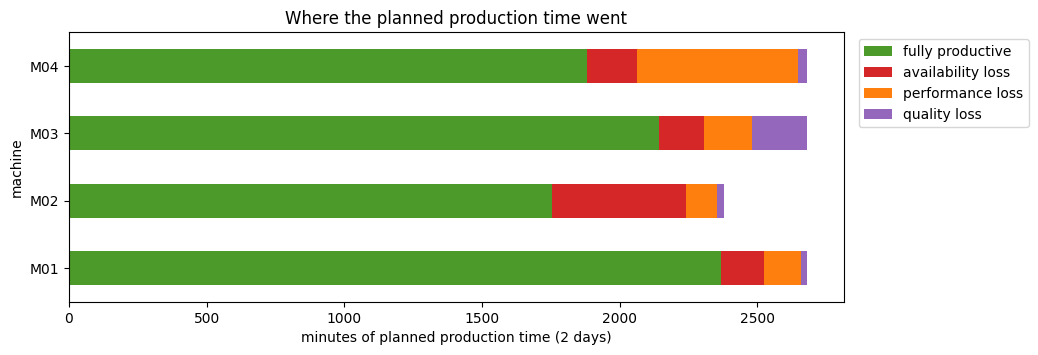

In [6]:
ax = loss[["fully productive", "availability loss", "performance loss", "quality loss"]].plot.barh(
    stacked=True, figsize=(10, 3.5), color=["#4c9a2a", "#d62728", "#ff7f0e", "#9467bd"])
ax.set_xlabel("minutes of planned production time (2 days)")
ax.set_ylabel("machine")
ax.set_title("Where the planned production time went")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

✍️ **Q A3.** For each machine, name its largest loss and one improvement action that targets it. Which machine would you visit first?

*Your answer:* Answer:

M01: Largest loss is availability loss (158 min), slightly higher than performance loss (133 min).
 Improvement action: Reduce downtime through preventive maintenance, faster troubleshooting, and standardized changeovers (SMED).

M02: Largest loss is availability loss (488 min) by a wide margin.
 Improvement action: Focus on breakdown reduction by performing root-cause analysis (5 Whys/FMEA), improving preventive maintenance, and addressing recurring failure modes.

M03: Largest loss is quality loss (200 min).
 Improvement action: Investigate causes of defects, monitor process capability, adjust tooling/process parameters, and strengthen quality checks to reduce scrap.

M04: Largest loss is performance loss (585 min), much larger than any other loss category.
 Improvement action: Increase operating speed by identifying minor stops and slow cycles, optimizing settings, improving operator training, and eliminating bottlenecks.

Which machine would I visit first?

I would visit M04 first because it has the single largest loss in the plant (585 min of performance loss) and also the lowest OEE among the machines. Recovering even a portion of this lost performance time would provide the greatest improvement in productive output. M02 also deserves attention because of its substantial downtime losses, but M04 represents the biggest improvement opportunity overall.

**A4. Six big losses and Pareto.** Map every lost minute to one of the six big losses — (1) equipment failure, (2) setup and adjustments, (3) idling and minor stops, (4) reduced speed, (5) start-up rejects, (6) production rejects — and sort them. The downtime log gives the first three by reason. Performance loss is used here for reduced speed, and quality loss for rejects (5 and 6 together, because the data does not separate them).

In [7]:
de = pd.read_csv("data/downtime_events.csv")
big_loss = {"Breakdown": "1 Equipment failure", "Setup / changeover": "2 Setup and adjustments",
            "Minor stop / jam": "3 Idling and minor stops"}
de["big_loss"] = de["reason"].map(big_loss)

# TODO A4: total minutes per big loss from the downtime log (group by "big_loss", sum "minutes")
minutes = de.groupby("big_loss")["minutes"].sum()
minutes["4 Reduced speed"] = loss["performance loss"].sum()
minutes["5+6 Rejects"] = loss["quality loss"].sum()

pareto = minutes.sort_values(ascending=False).to_frame("minutes")
pareto["cumulative %"] = 100 * pareto["minutes"].cumsum() / pareto["minutes"].sum()
pareto.round(1)

,minutes,cumulative %
big_loss,,
4 Reduced speed,1005.7,44.1
1 Equipment failure,470.0,64.7
5+6 Rejects,283.5,77.2
3 Idling and minor stops,280.0,89.5
2 Setup and adjustments,240.0,100.0


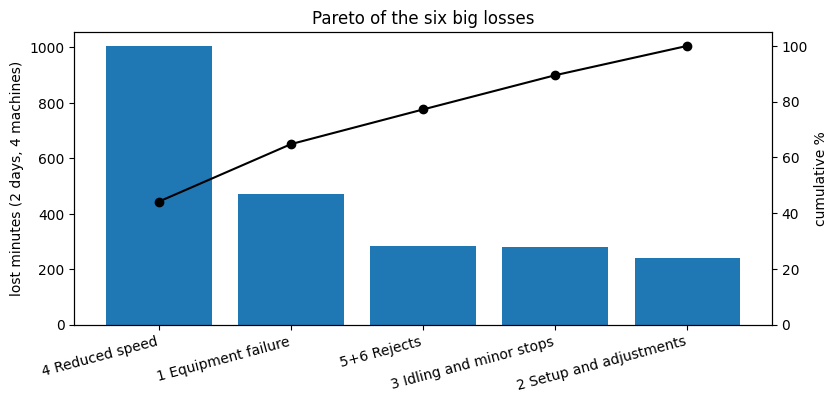

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(pareto.index, pareto["minutes"], color="#1f77b4")
ax.set_ylabel("lost minutes (2 days, 4 machines)")
ax2 = ax.twinx()
ax2.plot(pareto.index, pareto["cumulative %"], "o-", color="black")
ax2.set_ylim(0, 105); ax2.set_ylabel("cumulative %")
ax.set_title("Pareto of the six big losses")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right"); plt.show()

✍️ **Q A4.** Which two big losses together account for most of the lost time? Is the Pareto for the whole plant enough to decide what to do on each machine?

*Your answer:* Answer:

The Pareto analysis shows that the two largest losses are:

Reduced speed: 1005.7 minutes (44.1% of all lost time)
Equipment failure: 470.0 minutes (20.6% of all lost time)

Together they account for approximately 64.7% of the total lost time, so these are the dominant improvement opportunities for the plant.

However, the Pareto for the whole plant is not sufficient to decide what to do on each machine. The plant-level Pareto combines losses from all machines and can hide machine-specific problems:

M04 is mainly affected by reduced speed (performance loss), so efforts should focus on eliminating slow cycles and minor stoppages.
M02 is mainly affected by equipment failure (availability loss), so maintenance and reliability improvements are the priority.
M03 has its largest loss in quality, requiring defect reduction and process-control actions.
M01 has relatively small losses and may not be the first improvement target.

Therefore, the plant Pareto is useful for identifying the biggest overall loss categories, but effective improvement actions require a machine-level Pareto and loss analysis to target the root causes on each machine.

## Part B — Descriptive statistics and distributions (≈ 20 min)
Repair times (time to repair a breakdown, in minutes) are a typical manufacturing quantity: they cannot be negative, most repairs are short, a few are very long. What does that do to the statistics?

In [9]:
rt = pd.read_csv("data/repair_times.csv")["repair_min"]
# TODO B1: compute the descriptive statistics. Use the SAMPLE standard deviation (pandas .std() divides by n − 1).
desc = pd.Series({
    "n": len(rt),
    "mean": rt.mean(),
    "median": rt.median(),
    "std (s)": rt.std(),              # sample standard deviation (ddof=1)
    "CV = s / mean": rt.std() / rt.mean(),
    "skewness": rt.skew(),
    "excess kurtosis": rt.kurt(),
}).round(3)

desc

n                  300.000
mean                30.192
median              25.950
std (s)             20.515
CV = s / mean        0.679
skewness             2.279
excess kurtosis      7.990
dtype: float64

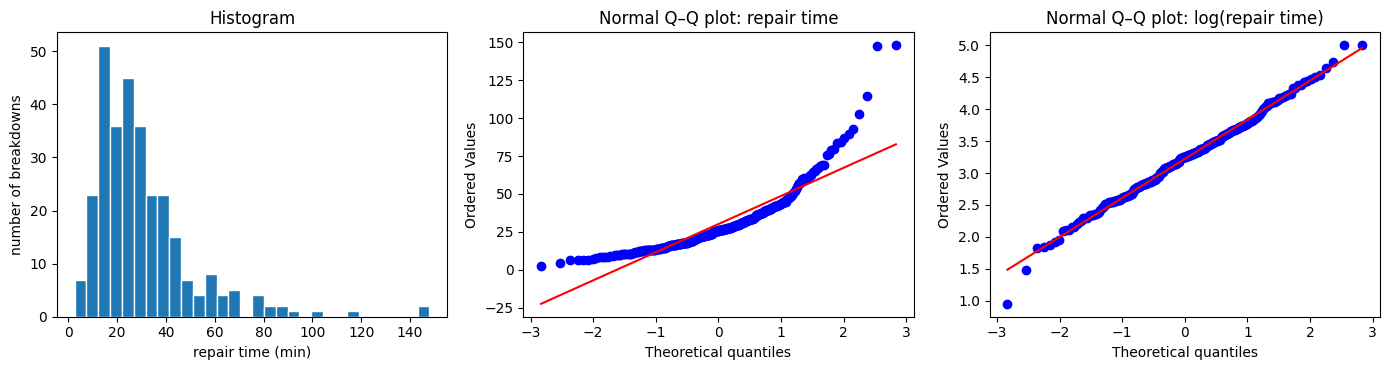

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].hist(rt, bins=30, color="#1f77b4", edgecolor="white")
axs[0].set_xlabel("repair time (min)"); axs[0].set_ylabel("number of breakdowns"); axs[0].set_title("Histogram")
stats.probplot(rt, dist="norm", plot=axs[1]); axs[1].set_title("Normal Q–Q plot: repair time")
stats.probplot(np.log(rt), dist="norm", plot=axs[2]); axs[2].set_title("Normal Q–Q plot: log(repair time)")
plt.tight_layout(); plt.show()

✍️ **Q B1.** Describe the shape using the mean versus median, skewness, kurtosis and the two Q–Q plots. Which distribution fits repair time, and why is that physically reasonable? Which value would you report as the 'typical' repair time?

*Your answer:* Answer:

The repair-time distribution is strongly right-skewed, not symmetric. This is evident because the mean (30.2 min) is noticeably larger than the median (26.0 min). A few very long repairs pull the mean upward, while most repairs are completed in a shorter time.

The statistics support this conclusion:

Skewness = 2.279, which is strongly positive and indicates a long right tail.
Excess kurtosis = 7.990, which is much greater than zero, showing heavy tails and more extreme values than a normal distribution.
The histogram shows many short repairs and a few very long repairs extending beyond 100 minutes.

The normal Q-Q plot shows substantial curvature and large deviations from the reference line in the upper tail, indicating that repair times are not normally distributed. In contrast, the Q-Q plot of log(repair time) is nearly a straight line, which suggests that the logarithm of repair time is approximately normal.

Therefore, a lognormal distribution is the best fit for the repair times. This is physically reasonable because repair duration is always positive and is influenced by several multiplicative factors such as fault severity, spare-part availability, diagnostic time, technician experience, and system complexity. Multiplicative processes commonly produce lognormal distributions.

For a "typical" repair time, I would report the median of 26.0 minutes rather than the mean of 30.2 minutes. The median is more representative of a typical breakdown because it is not heavily affected by the relatively small number of very long repairs, whereas the mean is pulled upward by those extreme events.

In [11]:
# TODO B2: what share of the repair times lies within mean ± 1 s, ± 2 s, ± 3 s?
# Hint: rt.between(m - k*s, m + k*s).mean()
m, s = rt.mean(), rt.std()

share = {
    k: rt.between(m - k*s, m + k*s).mean()
    for k in [1, 2, 3]
}

pd.DataFrame({
    "observed %": {k: round(100 * v, 1) for k, v in share.items()},
    "normal distribution %": {1: 68.3, 2: 95.4, 3: 99.73}
})


,observed %,normal distribution %
1,83.3,68.30
2,95.7,95.40
3,98.3,99.73


✍️ **Q B2.** Compare the observed shares with the normal values. What would go wrong if a maintenance planner assumed repair times are normal and planned 'mean + 2 s' as a safe upper bound?

*Your answer:* Answer:

The observed percentages differ noticeably from the normal-distribution values:

Range	Observed	NormalMean ± 1s	83.3%	68.3%
Mean ± 2s	95.7%	95.4%
Mean ± 3s	98.3%	99.73%

These differences occur because the repair times are not normally distributed. The distribution is strongly right-skewed with a long upper tail. As a result:

More observations than expected fall within ±1 standard deviation because many repair times are concentrated near the lower end of the distribution.
Fewer observations than expected fall within ±3 standard deviations because the long right tail contains more extreme repair times than a normal distribution would predict.

If a maintenance planner assumed repair times were normal and used mean + 2s as a "safe" upper bound, the estimate could be misleading. Under a normal distribution, about 97.7% of observations are expected to be below mean + 2s (only 2.3% exceed it). For these repair times, the right tail is heavier, so long repairs occur more often than the normal assumption predicts. This would cause the planner to underestimate the likelihood of unusually long repairs, leading to overly optimistic schedules, insufficient maintenance windows, and unexpected downtime overruns.

Because repair times are approximately lognormally distributed, it is better to model them using a lognormal distribution (or use empirical percentiles such as the 90th or 95th percentile) rather than relying on the normal-distribution 68-95-99.7 rule.

## Part C — Statistical process control and capability (≈ 30 min)
Every hour, five consecutive bores are measured (one **subgroup**). The specification is **25.000 ± 0.030 mm**, i.e. LSL = 24.970 mm and USL = 25.030 mm.

An **X̄–R chart** watches the subgroup mean (X̄, the process *location*) and the subgroup range (R, the short-term *spread*). Control limits come from the process itself, not from the specification. In **Phase I** we compute the limits from a period when the process was believed to be stable — here **subgroups 1–15** — and in **Phase II** we use those frozen limits to monitor new subgroups.

Constants for subgroups of n = 5: **A₂ = 0.577, D₃ = 0, D₄ = 2.114, d₂ = 2.326**.

In [12]:
bore = pd.read_csv("data/bore_diameter.csv")
xcols = ["x1", "x2", "x3", "x4", "x5"]
# TODO C1: subgroup mean and subgroup range (max − min) across the five columns of each row (axis=1)

bore["xbar"] = bore[xcols].mean(axis=1)

bore["R"] = (
    bore[xcols].max(axis=1)
    - bore[xcols].min(axis=1)
)

check(np.isclose(bore["xbar"].iloc[0], bore.loc[0, xcols].mean()) and (bore["R"] > 0).all(), "xbar and R computed", "check axis=1")
bore.head()

✅ xbar and R computed


,subgroup,time,x1,x2,x3,x4,x5,xbar,R
0,1,2026-11-09 06:30,25.0050,25.0010,25.0139,24.9961,24.9931,25.00182,0.0208
1,2,2026-11-09 07:30,25.0060,24.9952,24.9916,25.0093,25.0054,25.00150,0.0177
2,3,2026-11-09 08:30,24.9771,24.9946,24.9931,25.0072,25.0138,24.99716,0.0367
3,4,2026-11-09 09:30,25.0185,25.0076,24.9932,24.9929,24.9944,25.00132,0.0256
4,5,2026-11-09 10:30,25.0059,25.0121,24.9867,25.0069,25.0094,25.00420,0.0254


In [13]:
A2, D3, D4, d2 = 0.577, 0.0, 2.114, 2.326
phase1 = bore[bore["subgroup"] <= 15]
# TODO C2: centre lines and control limits from Phase I

# Centre lines
xbarbar = phase1["xbar"].mean()
Rbar = phase1["R"].mean()

# X-bar chart limits
UCL_x = xbarbar + A2 * Rbar
LCL_x = xbarbar - A2 * Rbar

# R chart limits
UCL_R = D4 * Rbar
LCL_R = D3 * Rbar

print(f"X-bar chart: CL = {xbarbar:.4f}, UCL = {UCL_x:.4f}, LCL = {LCL_x:.4f} mm")
print(f"R chart:     CL = {Rbar:.4f}, UCL = {UCL_R:.4f}, LCL = {LCL_R:.4f} mm")

X-bar chart: CL = 25.0018, UCL = 25.0141, LCL = 24.9896 mm
R chart:     CL = 0.0212, UCL = 0.0448, LCL = 0.0000 mm


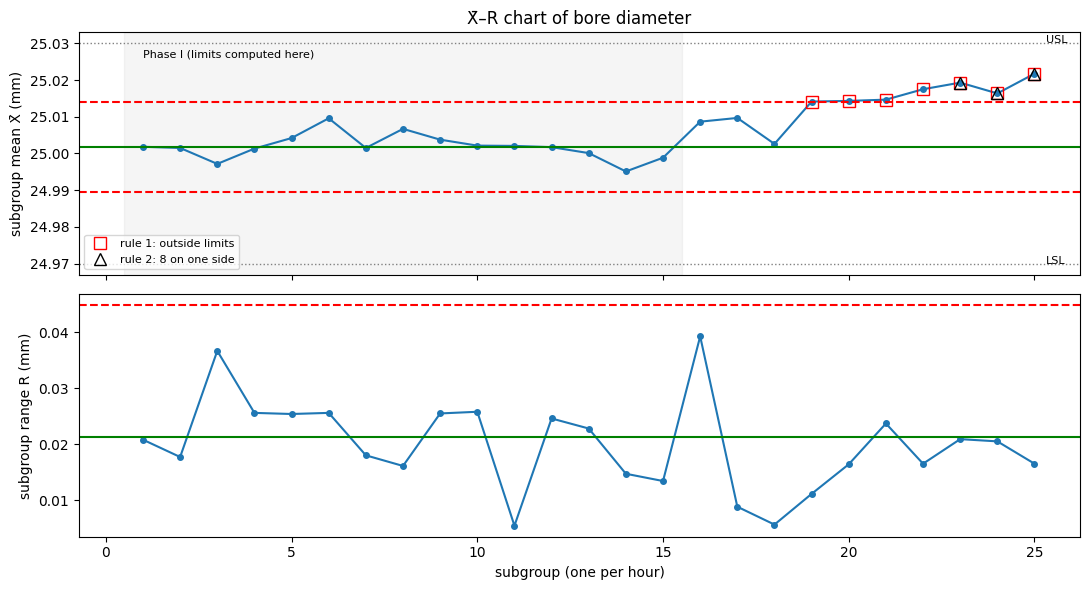

subgroups with a signal: [19, 20, 21, 22, 23, 24, 25]


In [14]:
# Signals (given): rule 1 = a point outside the control limits; rule 2 = 8 consecutive points on the same side of the centre line
bore["rule1"] = (bore["xbar"] > UCL_x) | (bore["xbar"] < LCL_x)
side = np.sign(bore["xbar"] - xbarbar)
bore["rule2"] = side.groupby((side != side.shift()).cumsum()).cumcount() + 1 >= 8

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
a1.plot(bore["subgroup"], bore["xbar"], "o-", ms=4)
for y, ls in [(UCL_x, "--"), (xbarbar, "-"), (LCL_x, "--")]: a1.axhline(y, color="red" if ls == "--" else "green", ls=ls)
for y in [24.970, 25.030]: a1.axhline(y, color="grey", ls=":", lw=1)
a1.plot(bore.loc[bore.rule1, "subgroup"], bore.loc[bore.rule1, "xbar"], "rs", ms=9, mfc="none", label="rule 1: outside limits")
a1.plot(bore.loc[bore.rule2, "subgroup"], bore.loc[bore.rule2, "xbar"], "k^", ms=8, mfc="none", label="rule 2: 8 on one side")
a1.axvspan(0.5, 15.5, color="grey", alpha=0.08); a1.text(1, 25.026, "Phase I (limits computed here)", fontsize=8)
a1.text(25.3, 25.030, "USL", fontsize=8); a1.text(25.3, 24.970, "LSL", fontsize=8)
a1.set_ylabel("subgroup mean X̄ (mm)"); a1.legend(loc="lower left", fontsize=8); a1.set_title("X̄–R chart of bore diameter")
a2.plot(bore["subgroup"], bore["R"], "o-", ms=4)
a2.axhline(UCL_R, color="red", ls="--"); a2.axhline(Rbar, color="green")
a2.set_ylabel("subgroup range R (mm)"); a2.set_xlabel("subgroup (one per hour)")
plt.tight_layout(); plt.show()
print("subgroups with a signal:", bore.loc[bore.rule1 | bore.rule2, "subgroup"].tolist())

✍️ **Q C1.** Read the two charts. Is the spread (R chart) stable? When did the location change, which rule detects it first, and what would you tell the operator? Note also: the specification limits are drawn as grey dotted lines — why must they never be used as control limits?
Answer:

The R chart (spread chart) appears to be stable and in statistical control. All subgroup ranges are within the control limits (LCL = 0.0000 mm, UCL = 0.0448 mm), and there are no obvious non-random patterns. This indicates that the short-term variability of the process has not changed; the process spread remains consistent over time.

The X̄ chart (location chart) tells a different story. Beginning around subgroup 19, the subgroup means shift upward and remain above the center line. This corresponds to the tool-wear effect that was introduced into the data.

The first signal is given by Rule 1 (point outside the control limits). Subgroup 19 is the first point that exceeds the UCL, indicating that the process mean has moved. Shortly afterward, Rule 2 (8 consecutive points on one side of the center line) is also triggered because the subsequent subgroup means stay consistently above the center line.

What I would tell the operator:

"The process variation is normal and stable, but the process average has shifted upward starting around subgroup 19. This suggests a systematic cause rather than random variation, most likely tool wear. The machine is still producing parts consistently, but it is centered too high. The tool should be inspected and adjusted or replaced before more out-of-control production occurs."

The specification limits (LSL and USL) must never be used as control limits because they answer different questions:

Control limits are calculated from the process data and indicate whether the process is statistically stable.
Specification limits are set by engineering/customer requirements and indicate whether parts meet design requirements.

A process can be:

In control but producing out-of-spec parts, or
Within specifications but out of control due to a process shift.

Using specification limits as control limits would delay detection of process changes and would not provide early warning of special causes such as the tool-wear shift seen here.

**C3. Capability.** Capability compares the specification width with the process spread.

- Short-term (within-subgroup) sigma: **σ_within = R̄ ÷ d₂** → **Cp = (USL − LSL) ÷ 6σ_within**, **Cpk = min(USL − μ, μ − LSL) ÷ 3σ_within**
- Long-term (overall) sigma: **σ_overall = sample standard deviation of all individual values** → **Pp** and **Ppk** with the same formulas.

Cp and Cpk are meaningful only for a **stable** process with enough data. We compute them for Phase I, and Pp/Ppk once for Phase I and once for all 25 subgroups.

In [15]:
LSL, USL = 24.970, 25.030
# TODO C3a: return the pair (index of spread, index of spread and centring) for a given sigma and mean
def cap(sigma, mu):
    cp = (USL - LSL) / (6 * sigma)
    cpk = min(
        (USL - mu) / (3 * sigma),
        (mu - LSL) / (3 * sigma)
    )
    return cp, cpk

sigma_within = Rbar / d2                 # Phase I within-subgroup sigma

all_p1 = phase1[xcols].to_numpy().ravel()
all_25 = bore[xcols].to_numpy().ravel()

cp, cpk = cap(sigma_within, all_p1.mean())
pp1, ppk1 = cap(all_p1.std(ddof=1), all_p1.mean())
pp25, ppk25 = cap(all_25.std(ddof=1), all_25.mean())

pd.DataFrame(
    {
        "sigma (mm)": [sigma_within, all_p1.std(ddof=1), all_25.std(ddof=1)],
        "mean (mm)": [all_p1.mean(), all_p1.mean(), all_25.mean()],
        "spread index": [cp, pp1, pp25],
        "centred index": [cpk, ppk1, ppk25],
    },
    index=[
        "Cp / Cpk (Phase I, within)",
        "Pp / Ppk (Phase I, overall)",
        "Pp / Ppk (all 25 subgroups)"
    ]
).round(4)

,sigma (mm),mean (mm),spread index,centred index
"Cp / Cpk (Phase I, within)",0.0091,25.0018,1.0968,1.0298
"Pp / Ppk (Phase I, overall)",0.0089,25.0018,1.1211,1.0526
Pp / Ppk (all 25 subgroups),0.0107,25.0067,0.9306,0.7240


✍️ **Q C3.** Interpret the table. Why are Cp and Pp almost equal in Phase I but Ppk much lower over all 25 subgroups? Would it be correct to quote one Cpk value for the whole day?

*Your answer:* Answer:

The capability table shows a clear difference between the stable Phase I process and the entire day's production.

During Phase I (subgroups 1–15), Cp ≈ 1.10 and Pp ≈ 1.12 are almost identical. This indicates that the short-term variation and the overall variation are nearly the same because the process was stable and centered during this period. Likewise, Cpk ≈ 1.03 and Ppk ≈ 1.05 are very similar, confirming that the process was operating consistently and close to the target.

When all 25 subgroups are included, Pp falls to 0.93 and Ppk falls further to 0.72. The main reason is the shift in the process mean after subgroup 19 due to tool wear. The process spread itself did not increase significantly (the R chart remained in control), but the process became off-center. Because Ppk measures both variation and centering, it drops much more than Cp/Pp when the mean moves toward the specification limit.

The large difference between Pp (0.93) and Ppk (0.72) over all 25 subgroups indicates that the process is not merely variable; it is poorly centered over the full period due to the mean shift. This is a signal of instability rather than a true reflection of a single, consistent process.

Therefore, it would not be correct to quote one Cpk value for the whole day. Cpk assumes a stable process operating around a consistent mean. Since the X̄ chart shows a special-cause shift after subgroup 19, the day's data actually contain two different process states: before and after tool wear. Reporting a single Cpk value would hide the underlying change and could lead to incorrect conclusions about capability. The correct approach is to first address the out-of-control condition, then calculate capability using only a stable period of operation (such as Phase I) or separately analyze the periods before and after the shift.

## Part D — A first machine-learning model: predicting scrap on M03 (≈ 35 min)
Part A showed that M03 loses time to scrap. Can we predict, *before final inspection*, which parts are likely to be scrap from the process data? This is a **classification** problem (the target is 0 = good or 1 = scrap). The data is in **production order** — that matters for how we test.

In [16]:
ml = pd.read_csv("data/part_process_data.csv")
print(ml.head())
print(f"\nscrap share: {ml['scrap'].mean():.3f}")
print(f"accuracy of a 'model' that always predicts good: {1 - ml['scrap'].mean():.3f}")

   part_id  tool_age_parts  spindle_temp_C  coolant_flow_lpm  feed_mm_rev  rework_flag  scrap
0   500001               0           60.01             18.80       0.2142            0      0
1   500002               1           61.72             17.69       0.1878            0      0
2   500003               2           60.83             21.77       0.2065            0      0
3   500004               3           65.53             17.71       0.1880            0      0
4   500005               4           61.38             19.42       0.2106            0      0

scrap share: 0.055
accuracy of a 'model' that always predicts good: 0.945


✍️ **Q D1.** A colleague is proud of a model with 94 % accuracy on this data. Why is that number meaningless here?

*Your answer:* Answer:

The 94% accuracy is meaningless because the dataset is highly imbalanced. The output shows:

Scrap rate = 5.5%
Good parts = 94.5%

A trivial model that simply predicts "good" for every part would already achieve 94.5% accuracy without using any process variables at all.

Therefore, a model with 94% accuracy is actually worse than the naive baseline, because it may not identify any scrap parts. In manufacturing, the important question is not how many good parts are correctly classified, but how well the model detects the relatively rare scrap parts.

For this problem, more informative metrics would be:

Precision: Of the parts predicted as scrap, how many are actually scrap?
Recall (Sensitivity): What percentage of all scrap parts are detected?
F1-score: Balance between precision and recall.
ROC-AUC or PR-AUC: Overall classification performance across decision thresholds.
Confusion matrix: Shows the numbers of true positives, false negatives, etc.

A model with 94% accuracy could still have 0% recall for scrap, making it useless for preventing defects. In an imbalanced manufacturing dataset, performance must be judged by the model's ability to identify the rare but costly scrap parts, not by overall accuracy alone.

**D2. Choose the features.** A feature may be used only if it is **known at the moment the prediction is made** — here, when the part leaves the machine, before final inspection. `rework_flag` is filled in by the inspector *after* final inspection, and `part_id` is just a serial number.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, accuracy_score

# process features only
features = [
    "tool_age_parts",
    "spindle_temp_C",
    "coolant_flow_lpm",
    "feed_mm_rev"
]

X, y = ml[features], ml["scrap"]

# first 75% train, last 25% test
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    shuffle=False
)

check(
    set(features) == {"tool_age_parts", "spindle_temp_C", "coolant_flow_lpm", "feed_mm_rev"} and X_te.index.min() == 1500,
    f"features correct; train = {len(X_tr)} parts, test = {len(X_te)} later parts",
    "check the feature list and shuffle"
)


✅ features correct; train = 1500 parts, test = 500 later parts


✍️ **Q D3.** Why do we use `shuffle=False` here instead of a random split?

*Your answer:* 

**D4. Train and evaluate.** The `Pipeline` first scales the features and then fits a logistic regression. Because the scaler is *inside* the pipeline, it learns its mean and standard deviation from the training data only — no information from the test set leaks into training.

In [18]:
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_tr, y_tr)
y_hat = model.predict(X_te)                   # uses the default threshold 0.5
tn, fp, fn, tp = confusion_matrix(y_te, y_hat).ravel()
print(f"confusion matrix:  TN = {tn}  FP = {fp}  FN = {fn}  TP = {tp}")
print(f"accuracy = {accuracy_score(y_te, y_hat):.3f}")

# TODO D4: recall = share of real scrap that was caught; precision = share of scrap alarms that were real scrap
recall = tp / (tp + fn)

precision = tp / (tp + fp)

print(f"recall = {recall:.3f}, precision = {precision:.3f}")

confusion matrix:  TN = 453  FP = 1  FN = 44  TP = 2
accuracy = 0.910
recall = 0.043, precision = 0.667


**D5. Choose the threshold from costs.** The model gives each part a probability of scrap. By default a part is flagged when that probability is above 0.5, but nothing makes 0.5 special. Suppose a **missed scrap part** (it reaches the customer) costs **₹2,000**, and a **false alarm** (a good part sent to extra inspection) costs **₹150**. Choose the threshold with the lowest total cost on the test set.

In [19]:
p = model.predict_proba(X_te)[:, 1]
rows = []
for t in np.arange(0.02, 0.61, 0.02):
    flag = (p >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_te, flag, labels=[0, 1]).ravel()
    rows.append({"threshold": round(t, 2), "FN": fn_, "FP": fp_, "recall": tp_ / (tp_ + fn_),
                 "cost (₹)": 2000 * fn_ + 150 * fp_})
costs = pd.DataFrame(rows)

# TODO D5: find the row with the lowest cost (Hint: costs.loc[costs["cost (₹)"].idxmin()])
best = costs.loc[costs["cost (₹)"].idxmin()]

print(best)
print(
    "cost at the default threshold 0.5:",
    int(costs.loc[(costs["threshold"] - 0.5).abs().idxmin(), "cost (₹)"])
)

threshold        0.060000
FN               9.000000
FP             163.000000
recall           0.804348
cost (₹)     42450.000000
Name: 2, dtype: float64
cost at the default threshold 0.5: 88150


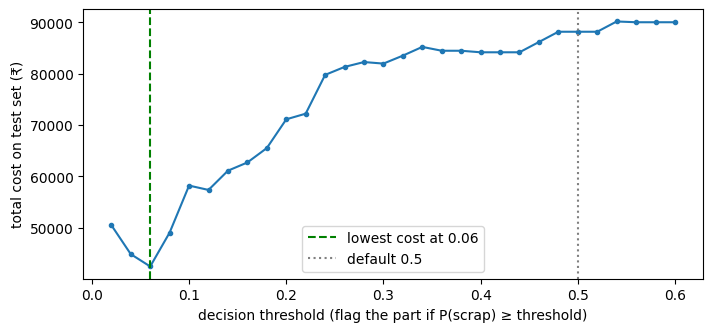

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(costs["threshold"], costs["cost (₹)"], "o-", ms=3)
ax.axvline(best["threshold"], color="green", ls="--", label=f"lowest cost at {best['threshold']:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax.set_xlabel("decision threshold (flag the part if P(scrap) ≥ threshold)"); ax.set_ylabel("total cost on test set (₹)")
ax.legend(); plt.show()

✍️ **Q D5.** Compare the lowest-cost threshold with the default 0.5: what happens to recall, to the number of false alarms and to the cost? Why is the best threshold so low?

*Your answer:* Answer (Q D5):

The lowest-cost threshold is 0.06, whereas the default threshold is 0.50.

Threshold	Recall	False Positives (FP)	Cost (₹)0.06 (lowest cost)	0.804 (80.4%)	163	42,450
0.50 (default)	Much lower	Much fewer	88,150
What happens compared with the default threshold (0.5)?

Recall increases significantly when the threshold is lowered to 0.06.

More truly defective/scrap parts are identified.
The number of false negatives (FN) drops to only 9.

False alarms (false positives) increase.

At 0.06, the model flags many more parts as scrap, giving 163 FP.
This is expected because a lower threshold classifies more observations as positive.

Total cost decreases dramatically.

Cost at 0.5 = ₹88,150
Cost at 0.06 = ₹42,450
Savings = ₹45,700 (about 52% lower cost).
Why is the best threshold so low?

The cost function heavily penalizes false negatives:

Cost=2000×FN+150×FP\text{Cost} = 2000 \times FN + 150 \times FP

A false negative costs ₹2,000, while a false positive costs only ₹150.

Therefore:

Missing a scrap part is more than 13 times as expensive as incorrectly flagging a good part.
Lowering the threshold catches many more scrap parts (reducing FN).
Although FP increases, the additional FP cost is relatively small compared with the large savings from avoiding expensive FN errors.

Hence, the cost-optimal strategy is to use a very low threshold (0.06), accepting more false alarms in exchange for substantially reducing the much costlier missed defects.

**D6. What leakage looks like.** Now add `rework_flag` to the features and train again with the same split.

In [21]:
leaky = make_pipeline(StandardScaler(), LogisticRegression())
leaky.fit(ml.loc[X_tr.index, features + ["rework_flag"]], y_tr)
y_leak = leaky.predict(ml.loc[X_te.index, features + ["rework_flag"]])
tn_, fp_, fn_, tp_ = confusion_matrix(y_te, y_leak).ravel()
print(f"with rework_flag:  accuracy = {accuracy_score(y_te, y_leak):.3f}, recall = {tp_/(tp_+fn_):.3f}, precision = {tp_/(tp_+fp_):.3f}")

with rework_flag:  accuracy = 1.000, recall = 1.000, precision = 1.000


✍️ **Q D6.** The model with `rework_flag` scores perfectly on the test set. Explain why it is useless on the shop floor, and name one other example of a leaking feature in manufacturing.

Answer:
1. Why the model is useless on the shop floor (Data Leakage):
The rework_flag feature causes target leakage (or temporal leakage) because it is only generated after a part has already been inspected, found to be defective, and sent for rework. On the actual shop floor, when a new part comes off the line and you need the model to predict whether it should be scrapped in real time, rework_flag does not exist yet (or is simply unknown at prediction time). Because the model relies entirely on an outcome that happens after the defect occurs, it cannot make predictions before inspection—making it completely useless for live production.  
2. Another example of a leaking feature in manufacturing:
Final Quality Control (QC) / Pass-Fail Inspection Status recorded at the end of the production line.
Scrap Bin Weight / Disposal Cost logged for that specific part ID.
Warranty Claim Flag or Customer Return ID recorded post-shipment.
Downtime / Maintenance Ticket ID logged specifically because that defective part jammed or halted the machine.


## Wrap-up
You computed **OEE** correctly (units, ratio of sums) and turned it into **lost minutes** and a **Pareto** of the six big losses; you saw why repair times are **lognormal** and why mean ± k·s misleads for skewed data; you built an **X̄–R chart**, found a **special cause** with run rules, and saw that **capability** is meaningful only for a stable process; and you trained a first **classifier** the right way — features known at prediction time, a time-ordered split, preprocessing inside a pipeline, recall and precision instead of accuracy, and a threshold chosen from costs.